In [2]:

!pip -q install kagglehub opencv-contrib-python-headless pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.5/69.5 MB 13.0 MB/s eta 0:00:00


In [3]:

import os
import kagglehub

# Download the specified dataset
path = kagglehub.dataset_download(
    "balabaskar/wonders-of-the-world-image-classification"
)

print("Dataset path:", path)

# Supported image formats
IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

# Display folders containing images
for root, dirs, files in os.walk(path):
    images = [f for f in files if f.lower().endswith(IMAGE_EXTS)]
    if images:
        print(f"{root} -> {len(images)} images")

100%|██████████| 432M/432M [00:26<00:00, 17.0MB/s]

Extracting files...


Dataset path: /root/.cache/kagglehub/datasets/balabaskar/wonders-of-the-world-image-classification/versions/2
/root/.cache/kagglehub/datasets/balabaskar/wonders-of-the-world-image-classification/versions/2/Wonders of World/Wonders of World/pyramids_of_giza -> 372 images
/root/.cache/kagglehub/datasets/balabaskar/wonders-of-the-world-image-classification/versions/2/Wonders of World/Wonders of World/machu_pichu -> 393 images
/root/.cache/kagglehub/datasets/balabaskar/wonders-of-the-world-image-classification/versions/2/Wonders of World/Wonders of World/burj_khalifa -> 390 images
/root/.cache/kagglehub/datasets/balabaskar/wonders-of-the-world-image-classification/versions/2/Wonders of World/Wonders of World/statue_of_liberty -> 238 images
/root/.cache/kagglehub/datasets/balabaskar/wonders-of-the-world-image-classification/versions/2/Wonders of World/Wonders of World/taj_mahal -> 158 images
/root/.cache/kagglehub/datasets/balabaskar/wonders-of-the-world-image-classification/versions/2/Wond

In [4]:

import cv2
import numpy as np
import random
from collections import defaultdict

random.seed(42)

# Find image files and infer class labels from their parent folders
all_images = []

for root, dirs, files in os.walk(path):
    for file in files:
        if file.lower().endswith(IMAGE_EXTS):
            full_path = os.path.join(root, file)
            label = os.path.basename(root)
            all_images.append((full_path, label))

if not all_images:
    raise RuntimeError(
        "No images found. Check the downloaded dataset folder structure."
    )

# Group images by folder label
images_by_label = defaultdict(list)
for img_path, label in all_images:
    images_by_label[label].append(img_path)

print("Available landmark classes:")
for label, files in sorted(images_by_label.items()):
    print(f"{label}: {len(files)} images")

# Landmark classes requested as examples in the lab
requested_landmarks = [
    "Eiffel Tower",
    "Taj Mahal",
    "Great Wall of China",
    "Statue of Liberty",
    "Colosseum"
]

def normalize_name(name):
    return "".join(ch.lower() for ch in name if ch.isalnum())

# Match requested names to actual dataset folder labels
selected_labels = []

for requested in requested_landmarks:
    target = normalize_name(requested)
    matches = [
        label for label in images_by_label
        if normalize_name(label) == target
        or target in normalize_name(label)
        or normalize_name(label) in target
    ]
    if matches:
        label = max(matches, key=lambda x: len(images_by_label[x]))
        if label not in selected_labels:
            selected_labels.append(label)

# Fill any missing slots with other available classes
for label in sorted(images_by_label, key=lambda x: len(images_by_label[x]), reverse=True):
    if label not in selected_labels and len(selected_labels) < 5:
        selected_labels.append(label)

selected_labels = selected_labels[:5]

if len(selected_labels) < 2:
    raise RuntimeError(
        "At least two landmark classes are needed for recognition."
    )

print("\nLandmark classes used:")
for label in selected_labels:
    print(f"- {label} ({len(images_by_label[label])} images)")

# Use multiple images per class when available
# Keep up to 10 images per class to make the notebook manageable
database = {}

for label in selected_labels:
    candidates = images_by_label[label][:]
    random.shuffle(candidates)
    database[label] = candidates[:10]

print("\nReference image database created.")
for label, files in database.items():
    print(f"{label}: {len(files)} reference images")

Available landmark classes:
burj_khalifa: 390 images
chichen_itza: 340 images
christ_the_reedemer: 323 images
eiffel_tower: 391 images
great_wall_of_china: 392 images
machu_pichu: 393 images
pyramids_of_giza: 372 images
roman_colosseum: 394 images
statue_of_liberty: 238 images
stonehenge: 204 images
taj_mahal: 158 images
venezuela_angel_falls: 251 images

Landmark classes used:
- eiffel_tower (391 images)
- taj_mahal (158 images)
- great_wall_of_china (392 images)
- statue_of_liberty (238 images)
- roman_colosseum (394 images)

Reference image database created.
eiffel_tower: 10 reference images
taj_mahal: 10 reference images
great_wall_of_china: 10 reference images
statue_of_liberty: 10 reference images
roman_colosseum: 10 reference images


Reference images processed: 50


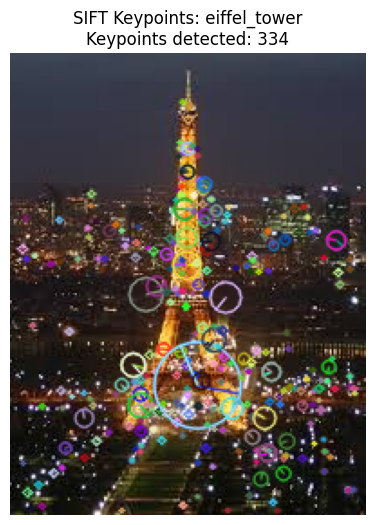

In [5]:

import matplotlib.pyplot as plt
import time
import pandas as pd

# Create the SIFT detector
sift = cv2.SIFT_create(nfeatures=2000)

# Store keypoints and descriptors for each reference image
reference_features = []

for label, image_paths in database.items():
    for image_path in image_paths:
        image = cv2.imread(image_path)

        if image is None:
            continue

        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        keypoints, descriptors = sift.detectAndCompute(gray, None)

        if descriptors is not None and len(keypoints) >= 4:
            reference_features.append({
                "label": label,
                "path": image_path,
                "image": image,
                "gray": gray,
                "keypoints": keypoints,
                "descriptors": descriptors
            })

print("Reference images processed:", len(reference_features))

if not reference_features:
    raise RuntimeError(
        "No usable SIFT features found. Check your images and OpenCV installation."
    )

# Display one reference image with detected keypoints
sample = reference_features[0]

keypoint_image = cv2.drawKeypoints(
    sample["image"],
    sample["keypoints"],
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(keypoint_image, cv2.COLOR_BGR2RGB))
plt.title(
    f"SIFT Keypoints: {sample['label']}\n"
    f"Keypoints detected: {len(sample['keypoints'])}"
)
plt.axis("off")
plt.show()

Saving images.jpeg to images.jpeg
Query image: images.jpeg
Query keypoints: 2000


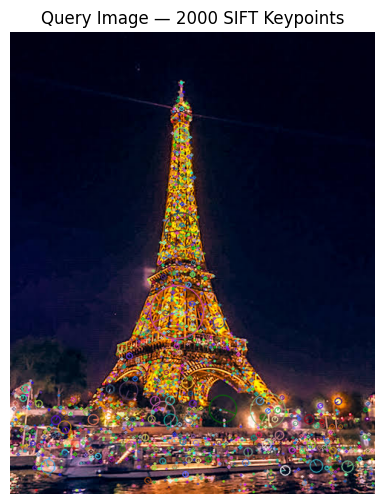

In [6]:

from google.colab import files
from IPython.display import display, Image

uploaded = files.upload()

if uploaded:
    query_filename = next(iter(uploaded))
    query_image = cv2.imread(query_filename)

    if query_image is None:
        raise ValueError("The uploaded file could not be read as an image.")

    print("Query image:", query_filename)
else:
    raise RuntimeError("Please upload a landmark image.")

query_gray = cv2.cvtColor(query_image, cv2.COLOR_BGR2GRAY)
query_keypoints, query_descriptors = sift.detectAndCompute(
    query_gray, None
)

print("Query keypoints:", len(query_keypoints))

query_visualization = cv2.drawKeypoints(
    query_image,
    query_keypoints,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

plt.figure(figsize=(9, 6))
plt.imshow(cv2.cvtColor(query_visualization, cv2.COLOR_BGR2RGB))
plt.title(f"Query Image — {len(query_keypoints)} SIFT Keypoints")
plt.axis("off")
plt.show()

LANDMARK RECOGNITION RESULT
Query keypoints: 2000
Processing time: 2.726 seconds
Decision: RECOGNIZED
Predicted landmark: statue_of_liberty
Reliable matches: 22
RANSAC inliers: 20
Inlier ratio: 0.91


,Landmark,Reliable Matches,RANSAC Inliers,Inlier Ratio
0,statue_of_liberty,22,20,0.909
1,taj_mahal,29,10,0.345
2,eiffel_tower,17,6,0.353
3,roman_colosseum,15,6,0.400
4,great_wall_of_china,20,4,0.200


Localization skipped: unreliable projected polygon.


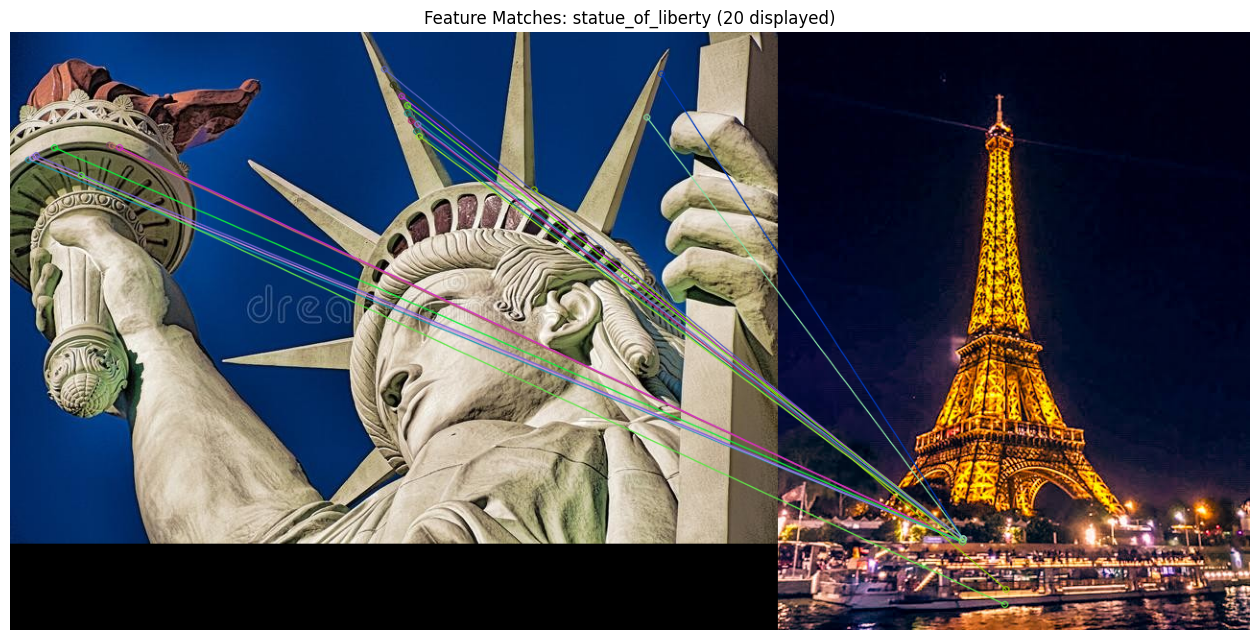

In [7]:

# Euclidean distance for SIFT descriptors
bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)

# Recognition thresholds: tune these after testing your dataset
MIN_RELIABLE_MATCHES = 8
MIN_RANSAC_INLIERS = 6
MIN_INLIER_RATIO = 0.25
LOWE_RATIO = 0.75

def match_reference(query_kp, query_desc, reference):
    """Match one reference image against the query image."""
    if query_desc is None or reference["descriptors"] is None:
        return [], None, 0, 0.0, None

    pairs = bf.knnMatch(
        reference["descriptors"],
        query_desc,
        k=2
    )

    # Lowe's ratio test
    good = [
        m for pair in pairs
        if len(pair) == 2
        for m, n in [pair]
        if m.distance < LOWE_RATIO * n.distance
    ]

    inlier_count = 0
    inlier_ratio = 0.0
    homography = None

    # Reference keypoints -> query keypoints
    if len(good) >= 4:
        src_pts = np.float32([
            reference["keypoints"][m.queryIdx].pt for m in good
        ]).reshape(-1, 1, 2)

        dst_pts = np.float32([
            query_kp[m.trainIdx].pt for m in good
        ]).reshape(-1, 1, 2)

        homography, mask = cv2.findHomography(
            src_pts,
            dst_pts,
            cv2.RANSAC,
            5.0
        )

        if homography is not None and mask is not None:
            inlier_count = int(mask.ravel().sum())
            inlier_ratio = inlier_count / len(good)

    return good, homography, inlier_count, inlier_ratio, (
        mask.ravel().astype(bool) if len(good) >= 4
        and homography is not None and mask is not None
        else None
    )

def recognize_landmark(query_image, show_output=True):
    start_time = time.perf_counter()

    query_gray = cv2.cvtColor(query_image, cv2.COLOR_BGR2GRAY)
    query_kp, query_desc = sift.detectAndCompute(query_gray, None)

    results = []

    if query_desc is not None:
        for reference in reference_features:
            good, H, inliers, inlier_ratio, mask = match_reference(
                query_kp, query_desc, reference
            )

            results.append({
                "landmark": reference["label"],
                "reference": reference,
                "good": good,
                "matches": len(good),
                "homography": H,
                "inliers": inliers,
                "inlier_ratio": inlier_ratio,
                "mask": mask
            })

    # Rank each landmark using its best reference image
    results.sort(
        key=lambda r: (r["inliers"], r["matches"], r["inlier_ratio"]),
        reverse=True
    )

    elapsed = time.perf_counter() - start_time

    best = results[0] if results else None

    recognized = (
        best is not None
        and best["matches"] >= MIN_RELIABLE_MATCHES
        and best["inliers"] >= MIN_RANSAC_INLIERS
        and best["inlier_ratio"] >= MIN_INLIER_RATIO
    )

    if show_output:
        print("=" * 55)
        print("LANDMARK RECOGNITION RESULT")
        print("=" * 55)
        print("Query keypoints:", len(query_kp))
        print(f"Processing time: {elapsed:.3f} seconds")

        if recognized:
            print("Decision: RECOGNIZED")
            print("Predicted landmark:", best["landmark"])
            print("Reliable matches:", best["matches"])
            print("RANSAC inliers:", best["inliers"])
            print(f"Inlier ratio: {best['inlier_ratio']:.2f}")
        else:
            print("Decision: REJECTED / INSUFFICIENT EVIDENCE")
            if best:
                print("Best candidate:", best["landmark"])
                print("Reliable matches:", best["matches"])
                print("RANSAC inliers:", best["inliers"])
                print(f"Inlier ratio: {best['inlier_ratio']:.2f}")

        # Display ranked candidates
        if results:
            ranking = pd.DataFrame([
                {
                    "Landmark": r["landmark"],
                    "Reliable Matches": r["matches"],
                    "RANSAC Inliers": r["inliers"],
                    "Inlier Ratio": round(r["inlier_ratio"], 3)
                }
                for r in results
            ])
            display(ranking.drop_duplicates("Landmark").reset_index(drop=True))

        # Display matches and localize the region if geometry is reliable
        if best and best["matches"] > 0:
            reference = best["reference"]
            good = best["good"]
            mask = best["mask"]
            H = best["homography"]

            if recognized and H is not None and best["inliers"] >= MIN_RANSAC_INLIERS:
                h, w = reference["gray"].shape
                corners = np.float32([
                    [0, 0], [w - 1, 0],
                    [w - 1, h - 1], [0, h - 1]
                ]).reshape(-1, 1, 2)

                projected = cv2.perspectiveTransform(corners, H)
                ih, iw = query_image.shape[:2]

                # Draw only if projected coordinates are finite and plausible
                pts = projected.reshape(-1, 2)
                valid = (
                    np.isfinite(pts).all()
                    and np.all(np.abs(pts) < 10 * max(ih, iw))
                    and cv2.isContourConvex(
                        np.round(pts).astype(np.int32).reshape(-1, 1, 2)
                    )
                )

                if valid:
                    localized = query_image.copy()
                    cv2.polylines(
                        localized,
                        [np.round(pts).astype(np.int32)],
                        True, (0, 255, 0), 4
                    )
                    print("Green polygon: estimated landmark location")
                    plt.figure(figsize=(10, 7))
                    plt.imshow(cv2.cvtColor(localized, cv2.COLOR_BGR2RGB))
                    plt.title("Landmark Localization")
                    plt.axis("off")
                    plt.show()
                else:
                    print("Localization skipped: unreliable projected polygon.")
            else:
                print("Localization skipped: insufficient geometric evidence.")

            # Draw reliable feature matches when possible
            if mask is not None and len(mask) == len(good):
                inlier_matches = [
                    m for m, keep in zip(good, mask) if keep
                ]
            else:
                inlier_matches = good

            if inlier_matches:
                match_image = cv2.drawMatches(
                    reference["image"],
                    reference["keypoints"],
                    query_image,
                    query_kp,
                    inlier_matches[:60],
                    None,
                    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
                )

                plt.figure(figsize=(16, 8))
                plt.imshow(cv2.cvtColor(match_image, cv2.COLOR_BGR2RGB))
                plt.title(
                    f"Feature Matches: {best['landmark']} "
                    f"({len(inlier_matches)} displayed)"
                )
                plt.axis("off")
                plt.show()

    return {
        "prediction": best["landmark"] if recognized else "Rejected",
        "best_candidate": best["landmark"] if best else "None",
        "recognized": recognized,
        "query_keypoints": len(query_kp),
        "matches": best["matches"] if best else 0,
        "inliers": best["inliers"] if best else 0,
        "processing_time": elapsed,
        "results": results,
        "query_keypoints_data": query_kp
    }

result = recognize_landmark(query_image)

In [8]:

def rotate_image(image, angle):
    h, w = image.shape[:2]
    matrix = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    return cv2.warpAffine(
        image, matrix, (w, h), borderMode=cv2.BORDER_REPLICATE
    )

def resize_test(image, scale=0.65):
    h, w = image.shape[:2]
    smaller = cv2.resize(
        image, (max(1, int(w * scale)), max(1, int(h * scale)))
    )
    return cv2.resize(smaller, (w, h))

def reduce_brightness(image, factor=0.5):
    return np.clip(image.astype(np.float32) * factor, 0, 255).astype(np.uint8)

test_images = {
    "Original": query_image,
    "Rotated": rotate_image(query_image, 15),
    "Resized": resize_test(query_image),
    "Reduced Brightness": reduce_brightness(query_image, 0.5)
}

evaluation_rows = []

for test_name, test_img in test_images.items():
    test_result = recognize_landmark(test_img, show_output=False)

    evaluation_rows.append({
        "Test Condition": test_name,
        "Predicted Landmark": test_result["prediction"],
        "Best Candidate": test_result["best_candidate"],
        "Query Keypoints": test_result["query_keypoints"],
        "Reliable Matches": test_result["matches"],
        "RANSAC Inliers": test_result["inliers"],
        "Decision": (
            "Recognized" if test_result["recognized"] else "Rejected"
        ),
        "Processing Time (s)": round(
            test_result["processing_time"], 3
        )
    })

evaluation_df = pd.DataFrame(evaluation_rows)

print("PERFORMANCE EVALUATION")
display(evaluation_df)

PERFORMANCE EVALUATION


,Test Condition,Predicted Landmark,Best Candidate,Query Keypoints,Reliable Matches,RANSAC Inliers,Decision,Processing Time (s)
0,Original,statue_of_liberty,statue_of_liberty,2000,22,20,Recognized,2.793
1,Rotated,taj_mahal,taj_mahal,2000,26,13,Recognized,2.797
2,Resized,statue_of_liberty,statue_of_liberty,2000,18,9,Recognized,2.725
3,Reduced Brightness,statue_of_liberty,statue_of_liberty,2000,24,20,Recognized,2.711


Upload an additional test image:


Saving images (1).jpeg to images (1).jpeg
LANDMARK RECOGNITION RESULT
Query keypoints: 1059
Processing time: 1.805 seconds
Decision: RECOGNIZED
Predicted landmark: roman_colosseum
Reliable matches: 44
RANSAC inliers: 13
Inlier ratio: 0.30


,Landmark,Reliable Matches,RANSAC Inliers,Inlier Ratio
0,roman_colosseum,44,13,0.295
1,great_wall_of_china,29,10,0.345
2,taj_mahal,27,9,0.333
3,statue_of_liberty,36,8,0.222
4,eiffel_tower,24,6,0.250


Localization skipped: unreliable projected polygon.


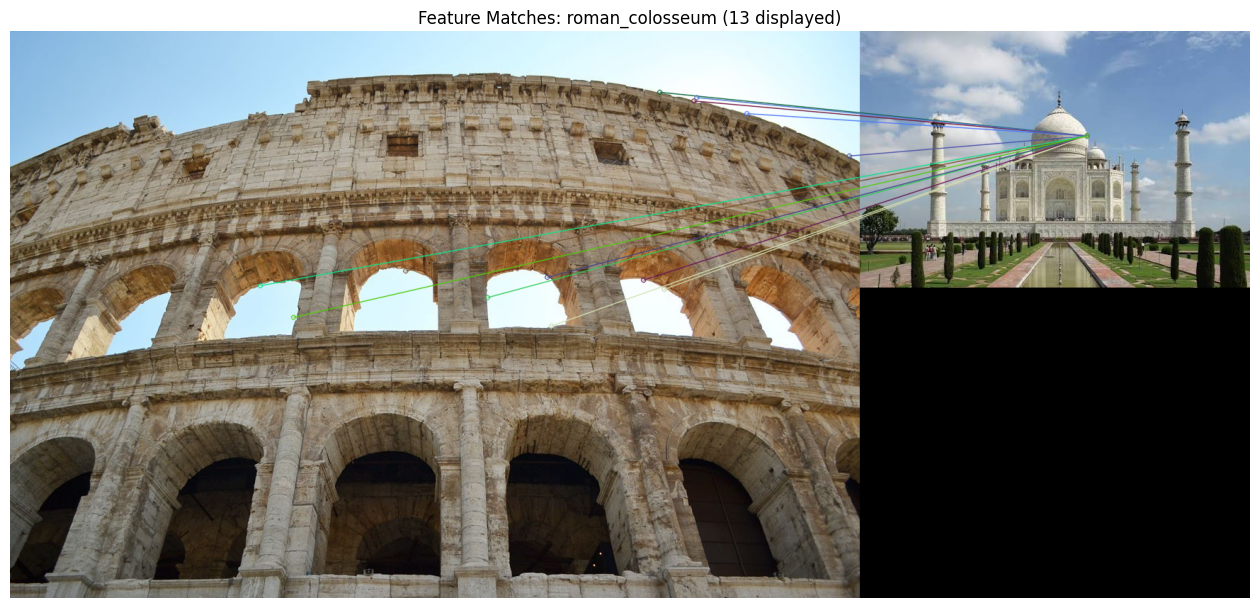


Additional test summary:


,Test Image,Predicted Landmark,Best Candidate,Query Keypoints,Reliable Matches,RANSAC Inliers,Decision,Processing Time (s)
0,images (1).jpeg,roman_colosseum,roman_colosseum,1059,44,13,Recognized,1.805


In [9]:

from google.colab import files

print("Upload an additional test image:")
extra_upload = files.upload()

if extra_upload:
    extra_filename = next(iter(extra_upload))
    extra_image = cv2.imread(extra_filename)

    if extra_image is not None:
        extra_result = recognize_landmark(extra_image)

        print("\nAdditional test summary:")
        display(pd.DataFrame([{
            "Test Image": extra_filename,
            "Predicted Landmark": extra_result["prediction"],
            "Best Candidate": extra_result["best_candidate"],
            "Query Keypoints": extra_result["query_keypoints"],
            "Reliable Matches": extra_result["matches"],
            "RANSAC Inliers": extra_result["inliers"],
            "Decision": (
                "Recognized" if extra_result["recognized"] else "Rejected"
            ),
            "Processing Time (s)": round(
                extra_result["processing_time"], 3
            )
        }]))